# Do the patterns predict on other coins?

On Bitcoin, only a few patterns looked promising, each with fewer than 20 signals. Here the full pattern set is run on **six other coins**
(ETH, SOL, BNB, XRP, ADA, DOGE) and the signals are pooled, so each pattern is judged on many more examples.
Bitcoin is then used as a reference: did its leads replicate on coins that were not used to find them?

**Method**
- Every detector reports a pattern on the first bar where it is complete; we enter at that bar's close, so no future data is used.
- For each pattern we measure the forward return in the pattern's direction and subtract the average return from entering on random bars of the same coin and period. This is the *excess*.
- **Earlier period** = before 2024. **Recent period** = 2024 onward.
- The p-value comes from a permutation test: how often the same number of random entries do at least as well.
- About 50 patterns are tested, so some look good by luck. The **q-value** corrects the recent p-values for this (Benjamini-Hochberg). **`edge holds`** requires a positive excess in both periods and q < 0.1; **`promising`** requires p < 0.1 but fails the correction.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

from cross_coin import (COINS, prepare, pooled_evaluate, summarize_pooled,
                        per_coin_table, active_signals, load_coin)
from pattern_backtest import DEFAULTS

TEST_START = '2024-01-01'
BLUE, ORANGE, AQUA, GRAY = '#2a78d6', '#eb6834', '#1baf7a', '#8a8984'
plt.rcParams.update({
    'figure.figsize': (11, 4.5), 'figure.dpi': 110, 'figure.facecolor': '#fcfcfb',
    'axes.facecolor': '#fcfcfb', 'axes.edgecolor': '#c3c2b7', 'axes.grid': True, 'axes.axisbelow': True,
    'grid.color': '#e6e5e0', 'grid.linewidth': 0.6, 'axes.spines.top': False,
    'axes.spines.right': False, 'lines.linewidth': 1.6, 'font.size': 10,
    'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.labelcolor': '#52514e',
    'xtick.color': '#52514e', 'ytick.color': '#52514e',
})
pd.set_option('display.width', 220)
pd.set_option('display.max_rows', 100)

FMT = {'is_hit_rate': 2, 'is_excess_pct': 2, 'is_p_value': 3, 'recent_hit_rate': 2,
       'recent_excess_pct': 2, 'recent_p_value': 3, 'recent_q': 3}
SHOW = ['is_n', 'is_hit_rate', 'is_excess_pct', 'is_p_value',
        'recent_n', 'recent_n_coins_pos', 'recent_hit_rate', 'recent_excess_pct', 'recent_p_value', 'recent_q', 'verdict']

daily = prepare(COINS, 'daily', TEST_START)
hourly = prepare(COINS, 'hourly', TEST_START)
btc_daily = prepare(['BTCUSDT'], 'daily', TEST_START, data_dir='.')
btc_hourly = prepare(['BTCUSDT'], 'hourly', TEST_START, data_dir='.')

overview = pd.DataFrame({
    s: {'daily bars': len(daily[s]['ohlc']), 'hourly bars': len(hourly[s]['ohlc']),
        'first date': daily[s]['ohlc'].index[0].date(), 'last date': daily[s]['ohlc'].index[-1].date(),
        'signals (daily)': len(daily[s]['events']), 'signals (hourly)': len(hourly[s]['events'])}
    for s in COINS}).T
overview

,daily bars,hourly bars,first date,last date,signals (daily),signals (hourly)
ETHUSDT,3208,76890,2018-01-01,2026-10-13,1646,37974
SOLUSDT,2255,54114,2020-08-11,2026-10-13,1144,26300
BNBUSDT,3208,76890,2018-01-01,2026-10-13,1613,37198
XRPUSDT,3085,73964,2018-05-04,2026-10-13,1556,36126
ADAUSDT,3102,74376,2018-04-17,2026-10-13,1548,36106
DOGEUSDT,2658,63756,2019-07-05,2026-10-13,1395,31775


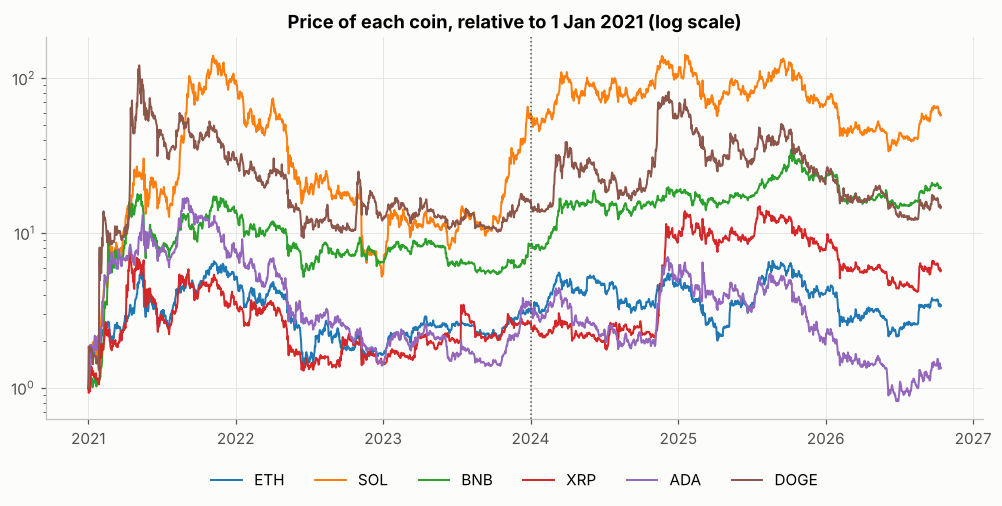

In [2]:
fig, ax = plt.subplots()
for s in COINS:
    c = daily[s]['ohlc']['close']
    c = c[c.index >= '2021-01-01']
    ax.plot(c.index, c / c.iloc[0], lw=1.3, label=s.replace('USDT', ''))
ax.set_yscale('log')
ax.set_title('Price of each coin, relative to 1 Jan 2021 (log scale)')
ax.axvline(pd.Timestamp(TEST_START), color='#52514e', ls=':', lw=1)
ax.legend(frameon=False, ncol=6, loc='upper center', bbox_to_anchor=(0.5, -0.1))
plt.show()

## 1. Daily bars: all patterns pooled across the six coins (5 days after the signal)

In [3]:
res_d = pooled_evaluate(daily, DEFAULTS['daily']['horizons'])
sum_d = summarize_pooled(res_d, 5)
print(sum_d['verdict'].value_counts().to_string(), '\n')
sum_d[SHOW].round(FMT)

verdict
too few       23
none          11
weak           7
promising      3
faded          2
edge holds     1 



,is_n,is_hit_rate,is_excess_pct,is_p_value,recent_n,recent_n_coins_pos,recent_hit_rate,recent_excess_pct,recent_p_value,recent_q,verdict
pattern,,,,,,,,,,,
double_bottom,87,0.48,0.52,0.349,48,5.0,0.60,3.29,0.007,0.090,edge holds
rectangle_up,43,0.56,2.76,0.089,34,4.0,0.41,2.42,0.064,0.221,promising
three_white_soldiers,59,0.69,3.75,0.017,61,5.0,0.48,2.22,0.036,0.216,promising
macd_hidden_bull_div,190,0.53,1.50,0.059,84,3.0,0.48,1.38,0.085,0.255,promising
rsi_hidden_bear_div,87,0.62,4.24,0.001,51,4.0,0.51,1.51,0.134,0.321,weak
rsi_hidden_bull_div,101,0.50,1.93,0.069,42,3.0,0.48,1.23,0.170,0.371,weak
rsi_bull_div,92,0.62,1.59,0.127,55,3.0,0.55,1.02,0.207,0.414,weak
three_black_crows,46,0.63,5.80,0.001,32,3.0,0.50,0.70,0.335,0.492,weak
bearish_engulfing,536,0.49,0.04,0.478,299,5.0,0.53,0.63,0.106,0.284,weak


**Scoreboard.** Each dot is one pattern (≥30 signals in each period). **x** = excess return before 2024, **y** = excess from 2024 on.
Patterns in the top-right beat random entries in both periods. Colored dots passed the verdict test; the size shows the number of recent signals.

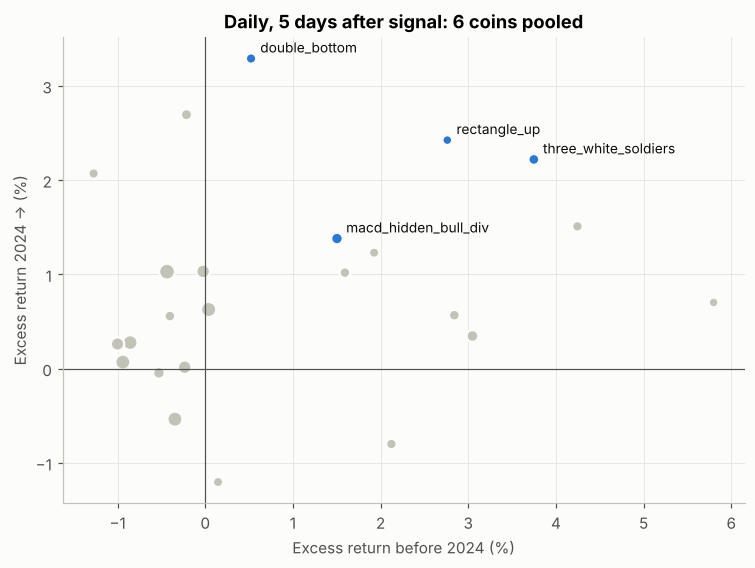

In [4]:
def scoreboard(summary, title, ax, min_n=30):
    s = summary[(summary['is_n'] >= min_n) & (summary['recent_n'] >= min_n)]
    strong = s['verdict'].isin(['edge holds', 'promising'])
    size = lambda d: 12 + 5 * np.sqrt(d['recent_n'])
    ax.axhline(0, color='#52514e', lw=0.8); ax.axvline(0, color='#52514e', lw=0.8)
    ax.scatter(s.loc[~strong, 'is_excess_pct'], s.loc[~strong, 'recent_excess_pct'], s=size(s[~strong]),
               color='#c3c2b7', edgecolor='#fcfcfb', lw=1.5)
    ax.scatter(s.loc[strong, 'is_excess_pct'], s.loc[strong, 'recent_excess_pct'], s=size(s[strong]),
               color=BLUE, edgecolor='#fcfcfb', lw=1.5)
    for name, row in s[strong].iterrows():
        ax.annotate(name, (row['is_excess_pct'], row['recent_excess_pct']), xytext=(6, 4),
                    textcoords='offset points', fontsize=9, color='#0b0b0b')
    ax.set_title(title); ax.set_xlabel('Excess return before 2024 (%)'); ax.set_ylabel('Excess return 2024 → (%)')

fig, ax = plt.subplots(figsize=(8, 5.5))
scoreboard(sum_d, 'Daily, 5 days after signal: 6 coins pooled', ax)
plt.show()

### How consistent is each promising pattern across coins? (daily, 5 days; excess % in the recent period)

In [5]:
top = sum_d.index[sum_d['verdict'].isin(['edge holds', 'promising', 'weak'])]
direction = {p: d for p, d in zip(daily['ETHUSDT']['events']['pattern'], daily['ETHUSDT']['events']['direction'])}
for c in COINS[1:]:
    direction.update({p: d for p, d in zip(daily[c]['events']['pattern'], daily[c]['events']['direction'])})

tbl = pd.DataFrame({p: per_coin_table(daily, p, direction[p], 5)['recent_excess_pct'] for p in top}).T
tbl.columns = [c.replace('USDT', '') for c in tbl.columns]
tbl['pooled'] = sum_d.loc[top, 'recent_excess_pct']
tbl['coins > 0'] = (tbl[[c.replace('USDT', '') for c in COINS]] > 0).sum(axis=1)
tbl.round(2).style.background_gradient(cmap='RdBu', vmin=-8, vmax=8, subset=[c.replace('USDT', '') for c in COINS] + ['pooled']).format('{:.2f}', subset=[c.replace('USDT', '') for c in COINS] + ['pooled'])

,ETH,SOL,BNB,XRP,ADA,DOGE,pooled,coins > 0
double_bottom,2.04,-0.31,3.93,2.28,0.15,8.82,3.29,5
rectangle_up,-5.51,1.19,-0.21,3.30,0.60,20.02,2.42,4
three_white_soldiers,4.97,-0.80,1.09,2.02,2.11,4.24,2.22,5
macd_hidden_bull_div,-0.14,0.91,1.02,-4.41,-1.14,12.33,1.38,3
rsi_hidden_bear_div,-0.91,2.72,-0.47,3.21,0.43,1.65,1.51,4
rsi_hidden_bull_div,-0.12,0.28,4.07,-4.98,-9.00,15.53,1.23,3
rsi_bull_div,-3.82,-0.13,-2.62,1.60,2.33,3.87,1.02,3
three_black_crows,4.06,1.52,-3.47,-0.75,1.44,-3.89,0.70,3
bearish_engulfing,0.15,0.72,-0.14,1.11,1.77,0.52,0.63,5
ascending_triangle_down,0.54,-1.06,4.43,2.60,-3.06,-0.52,0.57,3


## 2. Hourly bars: all patterns pooled (24 hours after the signal)

In [6]:
res_h = pooled_evaluate(hourly, DEFAULTS['hourly']['horizons'])
sum_h = summarize_pooled(res_h, 24)
print(sum_h['verdict'].value_counts().to_string(), '\n')
sum_h[SHOW].round(FMT)

verdict
none         22
faded        12
weak          6
promising     4
too few       4 



,is_n,is_hit_rate,is_excess_pct,is_p_value,recent_n,recent_n_coins_pos,recent_hit_rate,recent_excess_pct,recent_p_value,recent_q,verdict
pattern,,,,,,,,,,,
triple_top,207,0.49,0.71,0.036,113,5,0.62,1.07,0.003,0.132,promising
bull_flag,502,0.51,0.36,0.099,272,5,0.49,0.59,0.012,0.176,promising
ascending_triangle_up,945,0.49,0.31,0.052,469,4,0.51,0.45,0.006,0.132,promising
ascending_triangle_down,1476,0.49,0.37,0.005,700,6,0.55,0.25,0.053,0.471,promising
triple_bottom,182,0.51,0.47,0.126,108,3,0.52,0.24,0.287,1.000,weak
three_white_soldiers,1664,0.49,0.14,0.161,1061,4,0.50,0.15,0.119,0.721,weak
macd_hidden_bear_div,2873,0.48,0.09,0.200,1487,5,0.50,0.12,0.136,0.721,weak
bear_pennant,87,0.49,0.35,0.291,53,4,0.53,0.08,0.460,1.000,weak
double_top,1127,0.47,0.24,0.083,604,4,0.50,0.07,0.342,1.000,weak


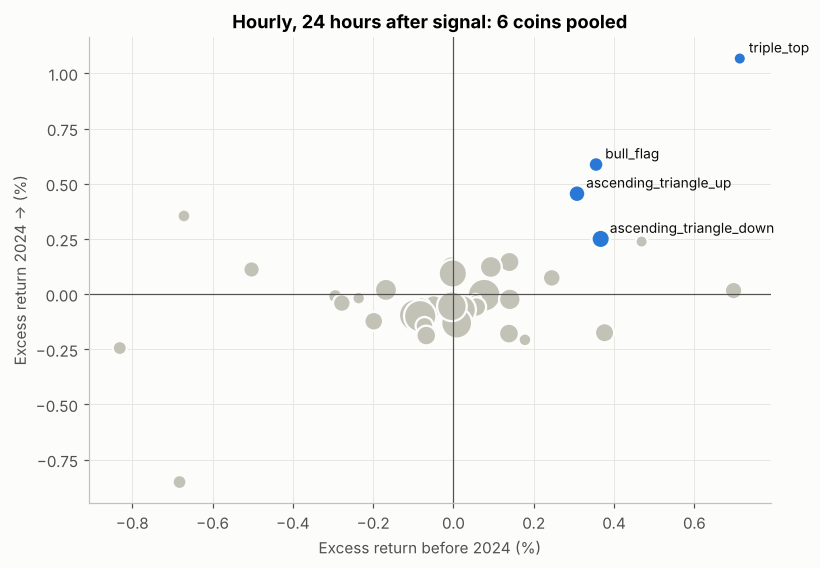

In [7]:
fig, ax = plt.subplots(figsize=(8, 5.5))
scoreboard(sum_h, 'Hourly, 24 hours after signal: 6 coins pooled', ax, min_n=100)
plt.show()

## 3. Did the Bitcoin leads replicate on other coins?

These were the patterns that looked best on Bitcoin. If they are real, they should also work on coins that were not used to find them.

In [8]:
btc_res_d = pooled_evaluate(btc_daily, DEFAULTS['daily']['horizons'])
btc_sum_d = summarize_pooled(btc_res_d, 5, min_n=5)
leads = ['double_top', 'macd_bear_div', 'rsi_bear_div', 'rsi_hidden_bull_div', 'rsi_hidden_bear_div']
rows = []
for p in leads:
    b, a = btc_sum_d.loc[p], sum_d.loc[p]
    rows.append({'pattern': p,
                 'BTC signals': b['recent_n'], 'BTC excess %': b['recent_excess_pct'],
                 'Alts signals': a['recent_n'], 'Alts excess %': a['recent_excess_pct'],
                 'Alts p-value': a['recent_p_value'], 'Alts coins > 0': a['recent_n_coins_pos'],
                 'Alts earlier-period excess %': a['is_excess_pct']})
lead_tbl = pd.DataFrame(rows).set_index('pattern')
print('Recent period (2024 ->), 5 days after signal')
lead_tbl.round(2)

Recent period (2024 ->), 5 days after signal


,BTC signals,BTC excess %,Alts signals,Alts excess %,Alts p-value,Alts coins > 0,Alts earlier-period excess %
pattern,,,,,,,
double_top,8,7.54,50,-0.80,0.73,2.0,2.12
macd_bear_div,18,2.40,66,2.69,0.01,5.0,-0.21
rsi_bear_div,9,2.11,47,2.07,0.05,4.0,-1.27
rsi_hidden_bull_div,13,2.81,42,1.23,0.17,3.0,1.93
rsi_hidden_bear_div,7,5.71,51,1.51,0.13,4.0,4.24


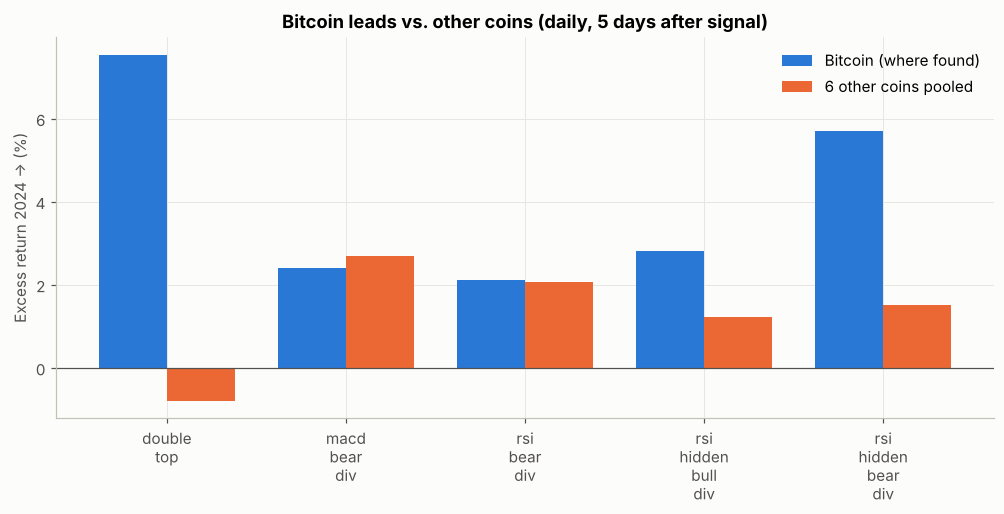

In [9]:
x = np.arange(len(leads)); w = 0.38
fig, ax = plt.subplots()
ax.bar(x - w/2, lead_tbl['BTC excess %'], w, color=BLUE, label='Bitcoin (where found)')
ax.bar(x + w/2, lead_tbl['Alts excess %'], w, color=ORANGE, label='6 other coins pooled')
ax.axhline(0, color='#52514e', lw=0.8)
ax.set_xticks(x); ax.set_xticklabels([l.replace('_', '\n') for l in leads])
ax.set_ylabel('Excess return 2024 → (%)')
ax.set_title('Bitcoin leads vs. other coins (daily, 5 days after signal)')
ax.legend(frameon=False)
plt.show()

## 4. Excess return by horizon for the leading patterns

In [10]:
def by_horizon(res, patterns):
    t = res[res['pattern'].isin(patterns)].pivot_table(index=['pattern', 'period'], columns='horizon', values='excess_pct')
    return t.round(2)

lead_d = sum_d.index[sum_d['verdict'].isin(['edge holds', 'promising'])]
lead_h = sum_h.index[sum_h['verdict'].isin(['edge holds', 'promising'])]
print('DAILY (days)'); display(by_horizon(res_d, lead_d))
print('HOURLY (hours)'); display(by_horizon(res_h, lead_h))

DAILY (days)


horizon                           1     5     10     20
pattern              period                            
double_bottom        in_sample -0.14  0.52  1.42  -0.05
                     recent     1.43  3.29  4.94   7.52
macd_hidden_bull_div in_sample -0.53  1.50  1.37   3.44
                     recent     0.07  1.38  1.08  -0.39
rectangle_up         in_sample -0.74  2.76  3.47   0.25
                     recent     0.76  2.42  4.30   6.35
three_white_soldiers in_sample -0.64  3.75  9.41  17.09
                     recent     1.34  2.22  4.47   9.71

HOURLY (hours)


horizon                             6     24    72    168
pattern                 period                           
ascending_triangle_down in_sample  0.24  0.37  0.19  0.02
                        recent     0.12  0.25  0.39  0.20
ascending_triangle_up   in_sample  0.15  0.31  0.41  0.35
                        recent    -0.03  0.45  0.27 -0.05
bull_flag               in_sample  0.18  0.36  0.76  1.55
                        recent     0.08  0.59  0.37 -0.02
triple_top              in_sample  0.24  0.71  0.71  0.44
                        recent     0.69  1.07  0.50  1.24

## 5. Current predictions

Patterns that fired recently on each coin, limited to the patterns rated `edge holds` or `promising` above.
`direction` is the predicted move over the next few days (daily) or hours (hourly).

In [11]:
sig_d = active_signals(daily, sum_d, lookback=10)
sig_h = active_signals(hourly, sum_h, lookback=48)
print('DAILY signals, last 10 days:')
display(sig_d.round({'price': 4, 'now': 4}) if len(sig_d) else 'none')
print('HOURLY signals, last 48 hours:')
display(sig_h.round({'price': 4, 'now': 4}) if len(sig_h) else 'none')

DAILY signals, last 10 days:


'none'

HOURLY signals, last 48 hours:


,coin,date,pattern,direction,price,now,verdict
0,ETHUSDT,2026-10-14 09:00:00,ascending_triangle_down,DOWN,2497.0400,2430.9800,promising
2,BNBUSDT,2026-10-14 11:00:00,ascending_triangle_down,DOWN,742.6400,729.7200,promising
1,SOLUSDT,2026-10-14 12:00:00,ascending_triangle_down,DOWN,105.4800,104.2100,promising
3,XRPUSDT,2026-10-14 12:00:00,ascending_triangle_down,DOWN,1.3579,1.3266,promising
4,DOGEUSDT,2026-10-14 12:00:00,ascending_triangle_down,DOWN,0.0833,0.0820,promising


## Conclusions

**Daily bars (5 days after the signal)**
- **MACD bearish divergence replicated.** On Bitcoin it gave +2.4% over random entries since 2024; on the six other coins it gave **+2.7%** (66 signals, 61% hit rate, 5 of 6 coins positive, p = 0.006). RSI bearish divergence showed the same on both (+2.1%).
- **Daily double bottom** is the top pooled pattern: **+3.3%** since 2024 (48 signals, 60% hit rate, 5 of 6 coins), and +7.5% by 20 days. It is the only one passing the multiple-testing correction (q = 0.09). Its earlier-period result was weak (+0.5%, not significant), so most of the evidence is recent.
- **Three white soldiers** and **rectangle breakouts upward** worked in both periods (+3.8% / +2.8% before 2024, +2.2% / +2.4% since), but are `promising`, not `edge holds` (q ≈ 0.22).
- **The Bitcoin double-top lead did not replicate**: +7.5% on Bitcoin (8 signals), **−0.8%** on the other coins (50 signals). It was most likely luck from a small sample.

**Hourly bars (24 hours after the signal)**
- 70+ patterns × coins were tested; **none** show a meaningful edge. The best (triple top, bull flag, ascending-triangle breakouts) earn only **0.25–1.1%** over 24 hours. A round trip on Binance costs about 0.2%, so after fees there is little or nothing left.
- Candlestick patterns (hammer, engulfing, doji, shooting star) do no better than random entries on any coin.

**Current predictions (as of Oct 14, 2026)**
- No daily signals from the leading patterns in the last 10 days.
- Hourly: ascending-triangle downside breakouts on ETH, BNB, SOL, XRP and DOGE, all within 3 hours of each other. This predicts a small further drop over the next 24 hours (typical excess +0.25%). Because it is the same market move showing up on 5 coins, count it as **one** signal, not five.

**Caveats**
- The coins move together, so pooled signals are not independent. The p-values are too optimistic, and `n_coins_pos` (how many coins agree) is the better test.
- Since 2024 the crypto market has been choppy, so patterns that work in a strong trend may not show up here.
- The best daily patterns have 34–66 signals in the recent period, enough to be interesting but not conclusive.

**Bottom line.** The most credible leads are **daily bearish divergences (MACD/RSI)**, **daily double bottom**, and **three white soldiers**. They are worth testing further with stop-losses and fees, but they are weak signals. Nothing on the hourly chart is worth trading.